# Практическая работа №7

## 1. Загрузка данных и преобразование индекса

Временной ряд — значения показателя, расположенные в порядке времени.

Для работы с датами используем индекс DatetimeIndex.

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt

url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv'
df = pd.read_csv(url)
df['Month'] = pd.to_datetime(df['Month'])
df = df.set_index('Month').asfreq('MS')

print(type(df.index))
print(df.head())

<class 'pandas.core.indexes.datetimes.DatetimeIndex'>
            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121


## 2. График исходного временного ряда

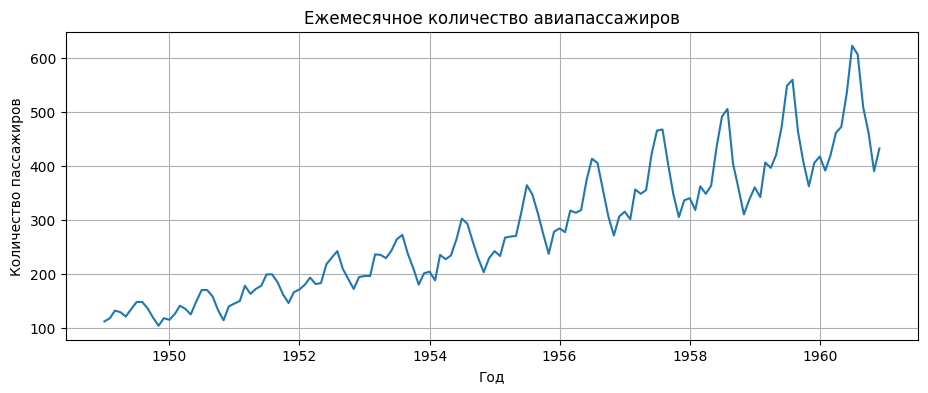

In [38]:
plt.figure(figsize=(11, 4))
plt.plot(df.index, df['Passengers'])
plt.title('Ежемесячное количество авиапассажиров')
plt.xlabel('Год')
plt.ylabel('Количество пассажиров')
plt.grid(True)
plt.show()

**Вывод:** Наблюдается восходящий тренд — число пассажиров со временем растёт. Также заметна сезонность: подъёмы и спады повторяются каждый год.

## 3. Декомпозиция временного ряда

Декомпозиция разделяет ряд на **тренд**, **сезонность** и **остаток**. Поскольку размах сезонных колебаний растёт вместе с уровнем ряда, используем мультипликативную модель:

$$
y_t = T_t \cdot S_t \cdot R_t
$$

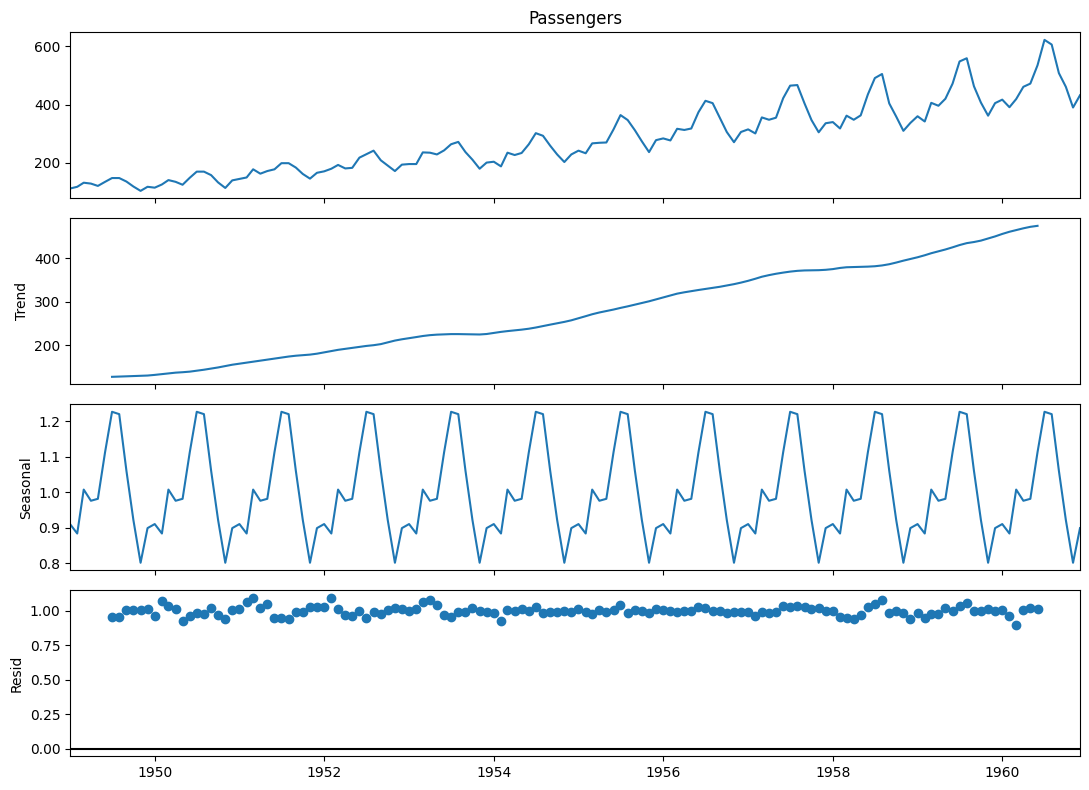

In [39]:
decomposition = seasonal_decompose(df['Passengers'], model='multiplicative', period=12)
fig = decomposition.plot()
fig.set_size_inches(11, 8)
plt.tight_layout()
plt.show()

**Вывод:** Тренд показывает общий рост, сезонная составляющая — ежегодные повторяющиеся колебания, а остаток — изменения, которые не объясняются трендом и сезонностью.

## 4. Сглаживание временного ряда

**Скользящее среднее** заменяет значения средним по соседним наблюдениям.
$$
\overline{y}_t = \frac{1}{m}\sum_{i=-p}^{p} y_{t+i}, \qquad p = \frac{m-1}{2}
$$

где $m$ — нечётный размер окна. Сравним окна **3, 7 и 13 месяцев**.

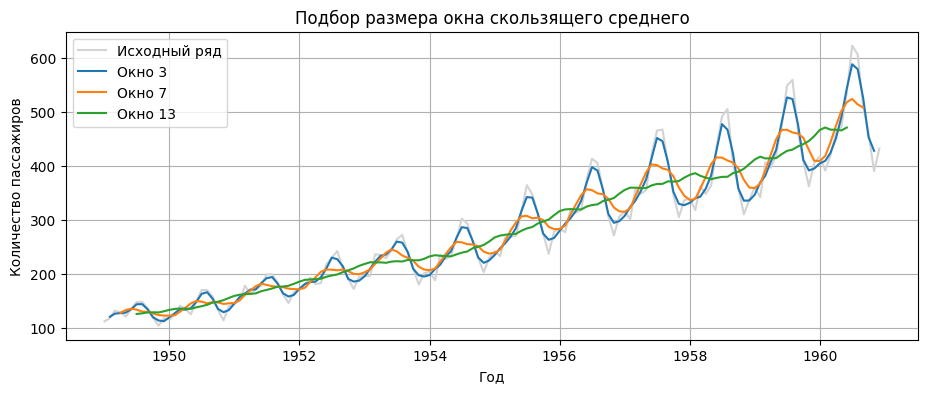

In [40]:
series = df['Passengers']
windows = [3, 7, 13]

plt.figure(figsize=(11, 4))
plt.plot(series, color='lightgray', label='Исходный ряд')
for window in windows:
    plt.plot(series.rolling(window=window, center=True).mean(), label=f'Окно {window}')
plt.title('Подбор размера окна скользящего среднего')
plt.xlabel('Год')
plt.ylabel('Количество пассажиров')
plt.legend()
plt.grid(True)
plt.show()





**Простое экспоненциальное сглаживание** придаёт больший вес недавним наблюдениям:

$$
S_t = \alpha y_t + (1-\alpha)S_{t-1}
$$

где $0<\alpha<1$ — коэффициент сглаживания. Возьмём $\alpha=0{,}2$ (в лекции рекомендуется диапазон 0,1–0,3). **Метод Хольта** дополнительно учитывает тренд.

In [41]:
moving_average = series.rolling(window=13, center=True).mean()
ses = SimpleExpSmoothing(series, initialization_method='estimated').fit(
    smoothing_level=0.2, optimized=False
)
holt = Holt(series, initialization_method='estimated').fit()

## 5. Визуализация результатов сглаживания

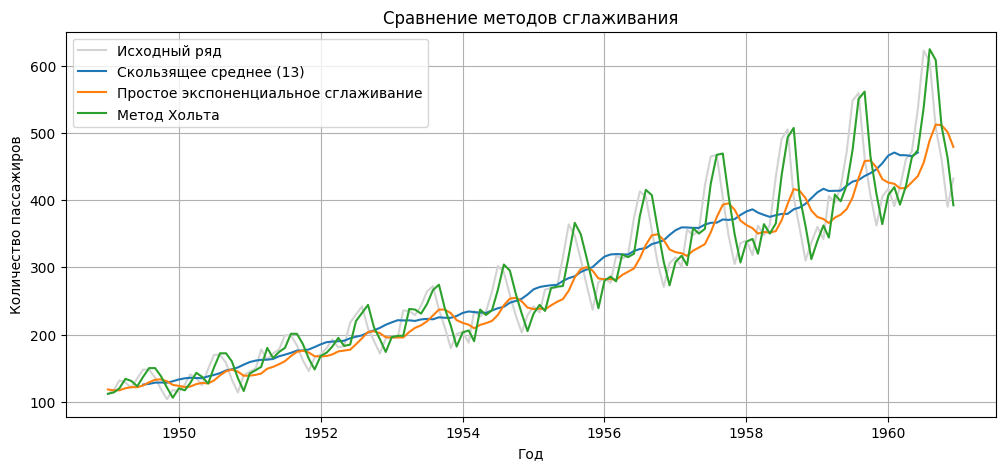

In [42]:
plt.figure(figsize=(12, 5))
plt.plot(series, label='Исходный ряд', color='lightgray')
plt.plot(moving_average, label='Скользящее среднее (13)')
plt.plot(ses.fittedvalues, label='Простое экспоненциальное сглаживание')
plt.plot(holt.fittedvalues, label='Метод Хольта')
plt.title('Сравнение методов сглаживания')
plt.xlabel('Год')
plt.ylabel('Количество пассажиров')
plt.legend()
plt.grid(True)
plt.show()

**Вывод:** Скользящее среднее убирает кратковременные колебания и выделяет тренд. Простое экспоненциальное сглаживание делает ряд более плавным. Метод Хольта учитывает рост показателя, поэтому лучше отслеживает восходящий тренд.

## Дополнительное задание. ACF и PACF

**ACF** показывает зависимость между значениями ряда при разных временных сдвигах (лагах). **PACF** показывает эту зависимость с учётом промежуточных лагов. Построим графики для исходного ряда.

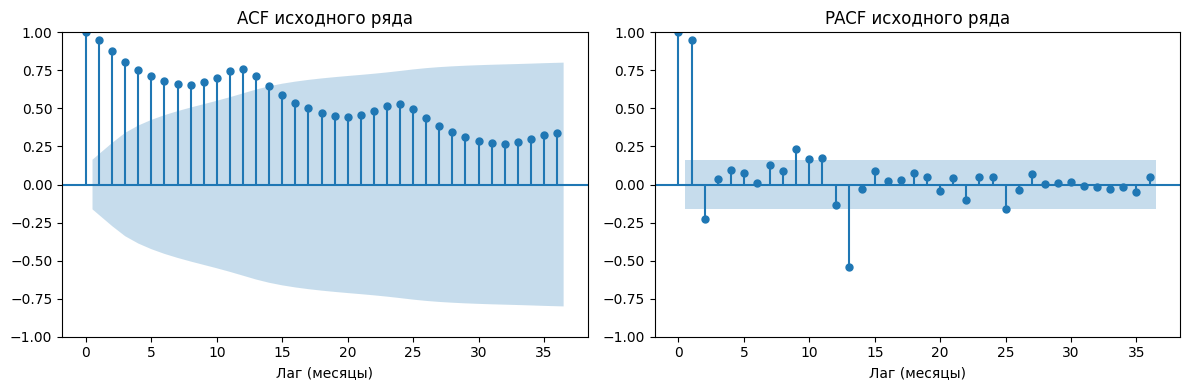

In [43]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(series, lags=36, ax=axes[0])
plot_pacf(series, lags=36, ax=axes[1], method='ywm')
axes[0].set_title('ACF исходного ряда')
axes[1].set_title('PACF исходного ряда')
axes[0].set_xlabel('Лаг (месяцы)')
axes[1].set_xlabel('Лаг (месяцы)')
plt.tight_layout()
plt.show()

**Вывод:** ACF показывает сильную зависимость соседних месяцев и сохранение корреляции на больших лагах из-за тренда и сезонности.